## Reading data from parquet

In [4]:
import pandas
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from pandas.core.tools.times import to_time

In [5]:
path = 'data/bitcoin_data.parquet'

In [17]:
data_raw = pq.read_pandas(path)

In [18]:
data_raw

pyarrow.Table
tx_id: string
conf_block_hash: string
found_at: timestamp[ns]
mined_at: timestamp[ns]
fee_rate_original: double
waittime: int64
weight_original: int64
size_original: int64
min_respend_blocks: int64
child_txid: string
rbf_fee_total: double
mempool_tx_count: double
mempool_size: double
total_output_amount: int64
absolute_fee_original: int64
weight: double
size: double
fee_rate: double
absolute_fee: double
vsize: double
has_corrected_weight: bool
label: string
n_in: int64
n_out: int64
has_op_return: int64
has_inscription: int64
block_height: int64
block_time: int64
block_tx_count: int64
block_total_weight: int64
block_median_feerate: double
block_p10_feerate: double
block_p90_feerate: double
time_since_last_block: double
gap_to_prev_block: double
ema_feerate_3block: double
is_cpfp_package: int64
found_at_ts: int64
epoch_id: int64
fee_rate_percentile: double
impatience: double
cumulative_weight: double
blockspace_utilization: double
log_weight: double
log_waittime: double
log

In [19]:
len(data_raw)

11110277

In [20]:
type(data_raw)

pyarrow.lib.Table

### Zmiana na pandas'a

In [21]:
data = data_raw.to_pandas()

In [22]:
data

,tx_id,conf_block_hash,found_at,mined_at,fee_rate_original,waittime,weight_original,size_original,min_respend_blocks,child_txid,...,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend,log_n_in,log_n_out,is_consolidation,is_coinjoin,is_datacarrying
0,e0062963708a3f49c89b6cb252a57808188a05752cf7db...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:27,1.0,2490,452,113,11,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.098612,0,0,0
1,766ade3892c0c796756c135f80adaea15545a89d1e8dfd...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:26,1.0,2489,548,137,3499,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.098612,0,0,0
2,4e491c09d81817d21afb647820c374143a30d7334b635e...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:40:57,2025-09-09 22:22:26,1.0,2489,576,144,3,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,1.386294,0,0,0
3,2a1f8638e69d39bb57c78f6e40558c61eccf857e1ddaea...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:41:14,2025-09-09 22:22:26,1.0,2472,328,82,35,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,0.693147,0.693147,0,0,0
4,ce72aa8d04042d3aa0ebc9588529adfcecedd0fbda5fd2...,00000000000000000000001032e11f7477824dee8b52f8...,2025-09-09 21:41:14,2025-09-09 22:22:25,1.0,2471,11808,2952,3,NaN,...,-0.707107,0.707107,0.781831,0.62349,0,4.276666,0.693147,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11110272,402fc499134d0f9a61df1d3f64dc973b7266997d454c42...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:38,3.0,29,732,183,35,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,0.693147,1.386294,0,0,1
11110273,05e746c504ef75534a0b729e72cc501a85ff90da45c7df...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:39,3.0,30,616,154,655,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,1.098612,1.098612,0,0,0
11110274,b3238a3931e970786a3d74701193f2adffa1b4e67f8a53...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:38,3.0,29,820,205,10,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,1.609438,0.693147,1,0,0
11110275,131c10ccd05131c463240ad48c1af79486d5a362d3bd84...,00000000000000000002336cb2668f135dc9a0114da1d0...,2025-08-03 21:54:09,2025-08-03 21:54:41,1.0,32,884,221,10,NaN,...,-0.707107,0.707107,-0.781831,0.62349,1,0.693147,1.609438,0,0,1


# Opis kolumn

In [9]:
import json

In [10]:
json_path = 'data/bitcoin_data.metadata.json'

In [11]:
metadata = None
with open(json_path) as f:
    metadata = json.load(f)


In [12]:
metadata

{'description': 'Analysis-ready dataset for Bitcoin fee estimation (VCG two-stage structural model)',
 'exported_at': '2026-03-26T18:09:52.538437',
 'n_transactions': 11110277,
 'n_columns': 67,
 'n_epochs': 1988,
 'time_range': {'start': '2025-08-03 06:27:44', 'end': '2025-10-09 20:44:20'},
 'n_blocks': 5965,
 'build_params': {'db_path': '/home/armin/datalake/data-samples/11-24-2025-15m-data-lake.db',
  'annotation_path': '/home/armin/datalake/data-samples/tx-annotations-15m-2-7-2026.pkl',
  'mempool_space_db': '/home/kristian/notebooks/mempool_space_data.db',
  'block_limit': None,
  'epoch_mode': 'time',
  'epoch_duration_minutes': 30},
 'columns': {'tx_id': {'dtype': 'object',
   'description': 'Transaction ID (hex string)'},
  'conf_block_hash': {'dtype': 'object',
   'description': 'Block hash where transaction was confirmed'},
  'found_at': {'dtype': 'datetime64[ns]',
   'description': 'Timestamp when transaction was first seen in mempool'},
  'mined_at': {'dtype': 'datetime64[n

In [11]:
columns_info = metadata['columns']
columns_info

{'tx_id': {'dtype': 'object', 'description': 'Transaction ID (hex string)'},
 'conf_block_hash': {'dtype': 'object',
  'description': 'Block hash where transaction was confirmed'},
 'found_at': {'dtype': 'datetime64[ns]',
  'description': 'Timestamp when transaction was first seen in mempool'},
 'mined_at': {'dtype': 'datetime64[ns]',
  'description': 'Timestamp when transaction was confirmed in a block'},
 'fee_rate_original': {'dtype': 'float64',
  'description': 'Original fee rate from source database before correction'},
 'waittime': {'dtype': 'int64',
  'description': 'Seconds between first mempool observation and block confirmation'},
 'weight_original': {'dtype': 'int64',
  'description': 'Original weight from source database'},
 'size_original': {'dtype': 'int64',
  'description': 'Original size from source database'},
 'min_respend_blocks': {'dtype': 'int64',
  'description': 'Minimum blocks until any input can be re-spent (-1 if unknown)'},
 'child_txid': {'dtype': 'object',


In [13]:
columns_info['tx_id']['description']

'Transaction ID (hex string)'

In [52]:
for column, values in columns_info.items():
    description = values['description'] if 'description' in values else 'no description'
    print(f"{column}: {description}")


tx_id: Transaction ID (hex string)
conf_block_hash: Block hash where transaction was confirmed
found_at: Timestamp when transaction was first seen in mempool
mined_at: Timestamp when transaction was confirmed in a block
fee_rate_original: Original fee rate from source database before correction
waittime: Seconds between first mempool observation and block confirmation
weight_original: Original weight from source database
size_original: Original size from source database
min_respend_blocks: Minimum blocks until any input can be re-spent (-1 if unknown)
child_txid: CPFP child transaction ID (if this tx is a CPFP parent)
rbf_fee_total: Total fee paid via RBF replacement (if applicable)
mempool_tx_count: Number of transactions in mempool when tx was observed
mempool_size: Mempool size in bytes when tx was observed
total_output_amount: Total output value in satoshis
absolute_fee_original: Original fee from source database
weight: Transaction weight in WU (corrected; CPFP package weight for 

### Opis ważniejszych kolumn

W danych mamy aż 64 kolumny.

Na temat bloku w którym potwierdzono tranzakcje:
* **conf_block_hash** - hash bloku, w którym potwierdzono tranzakcje
* **block_time**: czas wykopania bloku
* **block_median_feerate**: Median fee rate in the confirmation block (sat/vB)
* **block_p10_feerate**: 10th percentile fee rate in the confirmation block
* **block_p90_feerate**: 90th percentile fee rate in the confirmation block


Czas:
* **found_at**: przybycie tranzakcji do mempoola (timestamp)
* **mined_at**: potwierdzenie tranzakcji (timestamp)
* **waittime**: różnica pomiędzy dwoma powyższymi czasami

Opłaty:
* **fee_rate_original**: Original fee rate from source database before correction
* **rbf_fee_total: Total**: fee paid via RBF replacement (if applicable)
* **absolute_fee_original**: Original fee from source database
*
Rozmiar
* **weight_original**: Original weight from source database
* **size_original**: Original size from source database
* **size**: Transaction size in bytes (corrected)
* **vsize**: Virtual size in vB (corrected; CPFP package vsize for parents)





# Czasy pojawiania się tranzakcji

In [23]:
arrival_times = data['found_at']
arrival_times

0          2025-09-09 21:40:57
1          2025-09-09 21:40:57
2          2025-09-09 21:40:57
3          2025-09-09 21:41:14
4          2025-09-09 21:41:14
                   ...        
11110272   2025-08-03 21:54:09
11110273   2025-08-03 21:54:09
11110274   2025-08-03 21:54:09
11110275   2025-08-03 21:54:09
11110276   2025-08-03 21:54:09
Name: found_at, Length: 11110277, dtype: datetime64[ns]

In [24]:
type(arrival_times)

pandas.Series

In [25]:
type(arrival_times[0])

pandas.Timestamp

In [53]:
arrival_times = arrival_times.sort_values()
arrival_times

1299146   2025-08-03 06:27:44
1299149   2025-08-03 06:27:44
1299147   2025-08-03 06:27:44
1299148   2025-08-03 06:27:44
1299150   2025-08-03 06:27:45
                  ...        
5732515   2025-10-09 20:44:16
5732516   2025-10-09 20:44:17
5732518   2025-10-09 20:44:19
5732517   2025-10-09 20:44:19
5732519   2025-10-09 20:44:20
Name: found_at, Length: 11110277, dtype: datetime64[ns]

In [30]:
import matplotlib.pyplot as plt

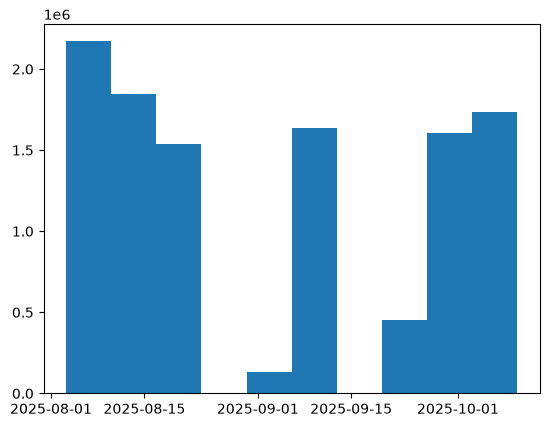

In [31]:
plt.hist(arrival_times)
plt.show()

# Wnioski

Jak widać na powyższym wykresie, dane nie były zbierane w sposób ciągły

In [39]:
def day(timestamp):
    return (timestamp.year, timestamp.month, timestamp.day)

In [41]:
days = [day(i) for i in arrival_times]
set(days)


{(2025, 8, 3),
 (2025, 8, 4),
 (2025, 8, 5),
 (2025, 8, 6),
 (2025, 8, 7),
 (2025, 8, 8),
 (2025, 8, 9),
 (2025, 8, 10),
 (2025, 8, 11),
 (2025, 8, 12),
 (2025, 8, 13),
 (2025, 8, 14),
 (2025, 8, 15),
 (2025, 8, 16),
 (2025, 8, 17),
 (2025, 8, 18),
 (2025, 8, 19),
 (2025, 8, 20),
 (2025, 8, 21),
 (2025, 8, 22),
 (2025, 9, 5),
 (2025, 9, 6),
 (2025, 9, 7),
 (2025, 9, 8),
 (2025, 9, 9),
 (2025, 9, 10),
 (2025, 9, 11),
 (2025, 9, 12),
 (2025, 9, 22),
 (2025, 9, 23),
 (2025, 9, 24),
 (2025, 9, 26),
 (2025, 9, 27),
 (2025, 9, 28),
 (2025, 9, 29),
 (2025, 9, 30),
 (2025, 10, 1),
 (2025, 10, 2),
 (2025, 10, 3),
 (2025, 10, 4),
 (2025, 10, 5),
 (2025, 10, 6),
 (2025, 10, 7),
 (2025, 10, 8),
 (2025, 10, 9)}

# Wnioski cd

Jak widzimy, dane były zbierane w 2025 roku:
* 3-22 sierpień
* 5-12 wrzesień
* 22 - 25 wrzesień
* 26 wrzesień - 9 październik

### Wykres gęstości

In [ ]:
import seaborn as sns

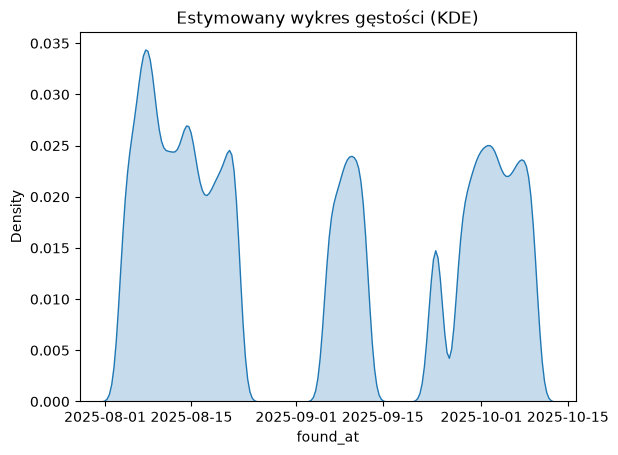

In [56]:
sns.kdeplot(arrival_times, fill=True)
plt.title('Estymowany wykres gęstości pojawiania się tranzakcji (KDE)')
plt.show()

# Czy są nanosekundy?

In [76]:
mask = [arrival_time.nanosecond != 0 for arrival_time in arrival_times]
sum(mask)

0

In [77]:
len(mask)

11110277

Nie ma nanosecund

## Czy są mikrosekundy?

In [81]:
mask = [arrival_time.microsecond != 0 for arrival_time in arrival_times]
sum(mask)

0

In [82]:
len(mask)

11110277

Też nie ma

# Czasy pojawiania sie nowych tranzakcji

In [64]:
waiting_times = arrival_times.diff()
waiting_times

1299146               NaT
1299149   0 days 00:00:00
1299147   0 days 00:00:00
1299148   0 days 00:00:00
1299150   0 days 00:00:01
                ...      
5732515   0 days 00:00:01
5732516   0 days 00:00:01
5732518   0 days 00:00:02
5732517   0 days 00:00:00
5732519   0 days 00:00:01
Name: found_at, Length: 11110277, dtype: timedelta64[ns]

### Usuwam pierwszy wyraz oraz czasy w których czas oczekiwania był większy niż 1 dzień

In [65]:
waiting_times = waiting_times[1:]
waiting_times = waiting_times[waiting_times < pd.Timedelta(days=1)]
waiting_times

1299149   0 days 00:00:00
1299147   0 days 00:00:00
1299148   0 days 00:00:00
1299150   0 days 00:00:01
1299151   0 days 00:00:00
                ...      
5732515   0 days 00:00:01
5732516   0 days 00:00:01
5732518   0 days 00:00:02
5732517   0 days 00:00:00
5732519   0 days 00:00:01
Name: found_at, Length: 11110273, dtype: timedelta64[ns]

### Zmiana typu na sekundy

In [84]:
waiting_times_seconds = waiting_times.astype(int)
waiting_times_seconds

1299149             0
1299147             0
1299148             0
1299150    1000000000
1299151             0
              ...    
5732515    1000000000
5732516    1000000000
5732518    2000000000
5732517             0
5732519    1000000000
Name: found_at, Length: 11110273, dtype: int64

In [89]:
waiting_times_seconds.value_counts()

found_at
0               8899005
1000000000      1773749
2000000000       283831
3000000000        55579
4000000000        17420
                 ...   
276000000000          1
222000000000          1
136000000000          1
207000000000          1
607000000000          1
Name: count, Length: 193, dtype: int64

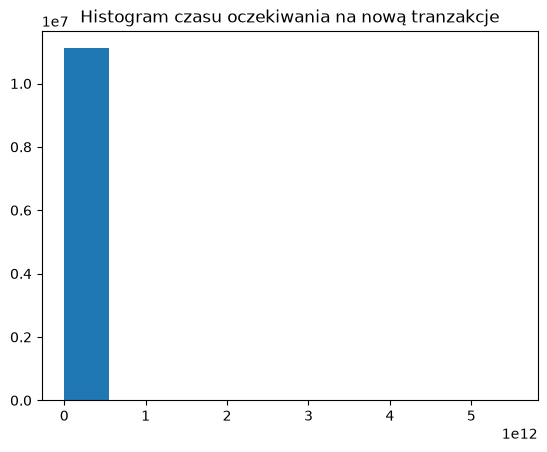

In [86]:
plt.hist(waiting_times_seconds)
plt.title("Histogram czasu oczekiwania na nową tranzakcje")
plt.show()

# Czasy oczekiwań na potwierdzenie

In [93]:
waittime = data['waittime']
waittime

0           2490
1           2489
2           2489
3           2472
4           2471
            ... 
11110272      29
11110273      30
11110274      29
11110275      32
11110276      32
Name: waittime, Length: 11110277, dtype: int64

In [96]:
waittime.sort_values()

7287832           0
7287831           0
7287830           0
9659359           0
9659358           0
             ...   
3162648     1014945
7510978     1055427
8383150     1155928
8383149     1156655
11031579    1172305
Name: waittime, Length: 11110277, dtype: int64

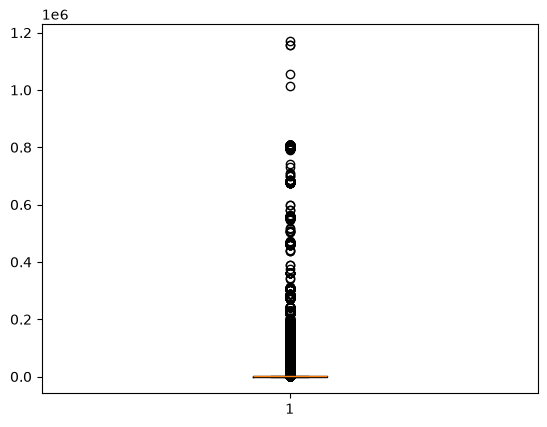

In [97]:
plt.boxplot(waittime)
plt.show()

In [ ]:
import s

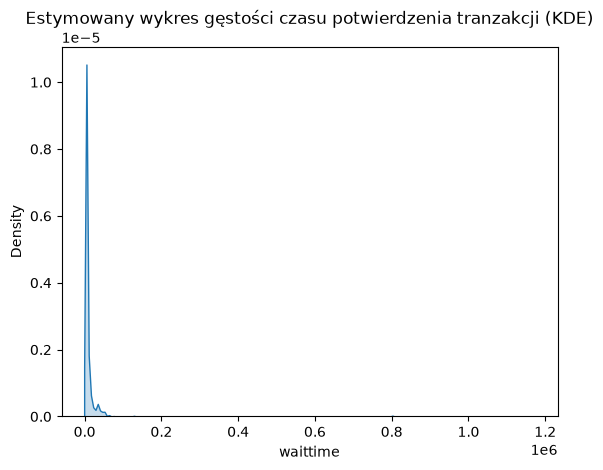

In [94]:
sns.kdeplot(waittime, fill=True)
plt.title('Estymowany wykres gęstości czasu potwierdzenia tranzakcji (KDE)')
plt.show()